In [6]:
from pathlib import Path
from urllib.request import urlopen

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)

In [8]:
# Localizar la carpeta principal del proyecto 

ruta_actual = Path.cwd().resolve()

if (ruta_actual / "data").exists() and (ruta_actual / "notebooks").exists():
    raiz_proyecto = ruta_actual
    
elif ruta_actual.name == "notebooks" and (ruta_actual.parent / "data").exists():
    raiz_proyecto = ruta_actual.parent
    
else:
    raise FileNotFoundError("No se pudo localizar la raíz del proyecto. Abre VS Code desde la carpeta Investigacion.")

print("Ubicación acutal: ", ruta_actual)
print("Raíz del proyecto: ", raiz_proyecto)

Ubicación acutal:  /Users/alexn/Documents/Uni_Itesm/Tercer semestre/F1009/Investigacion/notebooks
Raíz del proyecto:  /Users/alexn/Documents/Uni_Itesm/Tercer semestre/F1009/Investigacion


In [9]:
# Definir la ruta del Parquet integrado y comporbar que el archivo existe

ruta_parquet = raiz_proyecto / "data" / "interim" / "gmn_diciembre_2019_2025.parquet"

if not ruta_parquet.exists():
    raise FileNotFoundError(f"No se encontró la base integrada en: {ruta_parquet}")

tamano_parquet_mb = ruta_parquet.stat().st_size / 1024 ** 2

print("Archivo encontrado correctamente.")
print("Ruta: ", ruta_parquet)
print("Tamaño: ", round(tamano_parquet_mb, 2), "MB")

Archivo encontrado correctamente.
Ruta:  /Users/alexn/Documents/Uni_Itesm/Tercer semestre/F1009/Investigacion/data/interim/gmn_diciembre_2019_2025.parquet
Tamaño:  142.17 MB


In [10]:
# Cargar la base integrada desde el Parquet sin modificar el archivo guardado

print("Cargando la base integrada...")

df_base = pd.read_parquet(ruta_parquet, engine = "pyarrow")

memoria_df_mb = df_base.memory_usage(deep = True).sum() / 1024 ** 2

print("Carga completada.")
print("Filas: ", df_base.shape[0])
print("Columnas: ", df_base.shape[1])
print("Memoria utilizada por el DataFrame: ", round(memoria_df_mb, 2), "MB")


Cargando la base integrada...
Carga completada.
Filas:  382746
Columnas:  102
Memoria utilizada por el DataFrame:  292.41 MB


In [14]:
# Verificar correctamente que la base cargada coincide con la integración multianual

es_geminida = df_base["IAU (code)"].eq("GEM")

es_geminida_estandar = (
    es_geminida
    & df_base["calidad_estandar_provisional"].eq(True)
)

es_geminida_estricta = (
    es_geminida
    & df_base["calidad_estricta_provisional"].eq(True)
)

anios_obtenidos = sorted(
    int(anio)
    for anio in df_base["source_year"].dropna().unique()
)

anios_esperados = list(range(2019, 2026))

valores_obtenidos = [
    len(df_base),
    df_base.shape[1],
    df_base.columns.is_unique,
    df_base[
        "Unique trajectory (identifier)"
    ].duplicated().sum(),
    anios_obtenidos,
    int(es_geminida.sum()),
    int(es_geminida_estandar.sum()),
    int(es_geminida_estricta.sum()),
]

valores_esperados = [
    382746,
    102,
    True,
    0,
    anios_esperados,
    104678,
    19758,
    7268,
]

coincidencias = [
    len(df_base) == 382746,
    df_base.shape[1] == 102,
    df_base.columns.is_unique is True,
    (
        df_base[
            "Unique trajectory (identifier)"
        ].duplicated().sum()
        == 0
    ),
    anios_obtenidos == anios_esperados,
    int(es_geminida.sum()) == 104678,
    int(es_geminida_estandar.sum()) == 19758,
    int(es_geminida_estricta.sum()) == 7268,
]

comprobaciones = pd.DataFrame(
    {
        "comprobacion": [
            "Número de filas",
            "Número de columnas",
            "Nombres de columnas únicos",
            "Identificadores duplicados",
            "Años disponibles",
            "Gemínidas etiquetadas",
            "Gemínidas estándar",
            "Gemínidas estrictas",
        ],
        "valor_obtenido": valores_obtenidos,
        "valor_esperado": valores_esperados,
        "coincide": coincidencias,
    }
)

display(comprobaciones)

if not comprobaciones["coincide"].all():
    raise ValueError(
        "La base cargada no coincide con el resultado previamente validado."
    )

print("\nTodas las comprobaciones fueron superadas.")

,comprobacion,valor_obtenido,valor_esperado,coincide
0,Número de filas,382746,382746,True
1,Número de columnas,102,102,True
2,Nombres de columnas únicos,True,True,True
3,Identificadores duplicados,0,0,True
4,Años disponibles,"[2019, 2020, 2021, 2022, 2023, 2024, 2025]","[2019, 2020, 2021, 2022, 2023, 2024, 2025]",True
5,Gemínidas etiquetadas,104678,104678,True
6,Gemínidas estándar,19758,19758,True
7,Gemínidas estrictas,7268,7268,True



Todas las comprobaciones fueron superadas.


In [16]:
# Revisar los tipos y valores faltantes de las variables esenciales para el análisis físico

columnas_esenciales = [
    "Unique trajectory (identifier)",
    "Beginning (UTC Time)",
    "IAU (code)",
    "Sol lon (deg)",
    "RAgeo (deg)",
    "RAgeo_sigma",
    "DECgeo (deg)",
    "DECgeo_sigma",
    "LAMgeo (deg)",
    "BETgeo (deg)",
    "Vgeo (km/s)",
    "Vgeo_sigma",
    "Vavg (km/s)",
    "Vavg_sigma",
    "Peak (AbsMag)",
    "Peak Ht (km)",
    "Qc (deg)",
    "MedianFitErr (arcsec)",
    "Num (stat)",
    "source_year",
    "calidad_estandar_provisional",
    "calidad_estricta_provisional",
]

columnas_no_encontradas = [columna for columna in columnas_esenciales if columna not in df_base.columns]

if columnas_no_encontradas:
    raise ValueError(f"Faltan columnas esenciales: {columnas_no_encontradas}")

resumen_columnas_esenciales = pd.DataFrame(
    {
        "tipo": df_base[columnas_esenciales].dtypes.astype(str),
        "valores_disponibles": df_base[columnas_esenciales].notna().sum(),
        "valores_faltantes": df_base[columnas_esenciales].isna().sum(),
    }
)

resumen_columnas_esenciales["porcentaje_faltante"] = (100 * resumen_columnas_esenciales["valores_faltantes"] / len(df_base)).round(4)

display(resumen_columnas_esenciales)

,tipo,valores_disponibles,valores_faltantes,porcentaje_faltante
Unique trajectory (identifier),string,382746,0,0.0000
Beginning (UTC Time),"datetime64[us, UTC]",382746,0,0.0000
IAU (code),string,382746,0,0.0000
Sol lon (deg),float64,382746,0,0.0000
RAgeo (deg),float64,382746,0,0.0000
RAgeo_sigma,float64,382071,675,0.1764
DECgeo (deg),float64,382746,0,0.0000
DECgeo_sigma,float64,382071,675,0.1764
LAMgeo (deg),float64,382746,0,0.0000
BETgeo (deg),float64,382746,0,0.0000


In [18]:
tabla_muestras = pd.DataFrame(
    {
        "anio": df_base["source_year"].astype(int),
        "trayectoria": np.ones(len(df_base), dtype=int),
        "geminida": es_geminida.astype(int),
        "geminida_estandar": es_geminida_estandar.astype(int),
        "geminida_estricta": es_geminida_estricta.astype(int),
    }
)

resumen_anual_muestras = tabla_muestras.groupby("anio", as_index = False).sum()

resumen_anual_muestras["retencion_estandar_porcentaje"] = (100 * resumen_anual_muestras["geminida_estandar"] / resumen_anual_muestras["geminida"]).round(2)
resumen_anual_muestras["retencion_estricta_porcentaje"] = (100 * resumen_anual_muestras["geminida_estricta"] / resumen_anual_muestras["geminida"]).round(2)

display(resumen_anual_muestras)

,anio,trayectoria,geminida,geminida_estandar,geminida_estricta,retencion_estandar_porcentaje,retencion_estricta_porcentaje
0,2019,11143,2117,443,99,20.93,4.68
1,2020,17829,5959,1051,191,17.64,3.21
2,2021,33059,9968,2023,322,20.29,3.23
3,2022,45785,15800,3769,1776,23.85,11.24
4,2023,67520,19655,3538,1335,18.00,6.79
5,2024,89364,13814,2622,621,18.98,4.50
6,2025,118046,37365,6312,2924,16.89,7.83


In [19]:
# Crear copias independientes de las Gemínidas de catálogo, estándar y estrictas

mascara_gem_catalogo = df_base["IAU (code)"].eq("GEM")
mascara_gem_estandar = mascara_gem_catalogo & df_base["calidad_estandar_provisional"].eq(True)
mascara_gem_estricta = mascara_gem_catalogo & df_base["calidad_estricta_provisional"].eq(True)

df_gem_catalogo = df_base.loc[mascara_gem_catalogo].copy()
df_gem_estandar = df_base.loc[mascara_gem_estandar].copy()
df_gem_estricta = df_base.loc[mascara_gem_estricta].copy()

print("Gemínidas de catálogo:", len(df_gem_catalogo))
print("Gemínidas estándar:", len(df_gem_estandar))
print("Gemínidas estrictas:", len(df_gem_estricta))
print("Filas conservadas en df_base:", len(df_base))

Gemínidas de catálogo: 104678
Gemínidas estándar: 19758
Gemínidas estrictas: 7268
Filas conservadas en df_base: 382746


In [21]:
# Comprobar que las tres muestras cumplen correctamente sus condiciones de selección

comprobaciones_seleccion = pd.DataFrame(
    {
        "comprobacion": [
            "Todas las filas de catálogo tienen código GEM",
            "Todas las estándar tienen código GEM",
            "Todas las estándar superan calidad estándar",
            "Todas las estrictas tienen código GEM",
            "Todas las estrictas superan calidad estándar",
            "Todas las estrictas superan calidad estricta",
            "La muestra estricta está contenida en la estándar",
            "No hay IDs duplicados en catálogo",
            "No hay IDs duplicados en estándar",
            "No hay IDs duplicados en estricta",
            "df_base conserva todas sus filas",
        ],
        "resultado": [
            df_gem_catalogo["IAU (code)"].eq("GEM").all(),
            df_gem_estandar["IAU (code)"].eq("GEM").all(),
            df_gem_estandar["calidad_estandar_provisional"].eq(True).all(),
            df_gem_estricta["IAU (code)"].eq("GEM").all(),
            df_gem_estricta["calidad_estandar_provisional"].eq(True).all(),
            df_gem_estricta["calidad_estricta_provisional"].eq(True).all(),
            df_gem_estricta.index.isin(df_gem_estandar.index).all(),
            df_gem_catalogo["Unique trajectory (identifier)"].duplicated().sum() == 0,
            df_gem_estandar["Unique trajectory (identifier)"].duplicated().sum() == 0,
            df_gem_estricta["Unique trajectory (identifier)"].duplicated().sum() == 0,
            len(df_base) == 382746,
        ],
    }
)

display(comprobaciones_seleccion)

if not comprobaciones_seleccion["resultado"].all():
    raise ValueError("Alguna muestra no cumple las condiciones de selección.")

print("\nLa jerarquía de las muestras es correcta.")

,comprobacion,resultado
0,Todas las filas de catálogo tienen código GEM,True
1,Todas las estándar tienen código GEM,True
2,Todas las estándar superan calidad estándar,True
3,Todas las estrictas tienen código GEM,True
4,Todas las estrictas superan calidad estándar,True
5,Todas las estrictas superan calidad estricta,True
6,La muestra estricta está contenida en la estándar,True
7,No hay IDs duplicados en catálogo,True
8,No hay IDs duplicados en estándar,True
9,No hay IDs duplicados en estricta,True



La jerarquía de las muestras es correcta.


In [23]:
# Comprobar que la muestra estándar tiene completas las variables necesarias para el análisis físico

columnas_analisis_fisico = [
    "Unique trajectory (identifier)",
    "Beginning (UTC Time)",
    "Sol lon (deg)",
    "RAgeo (deg)",
    "DECgeo (deg)",
    "LAMgeo (deg)",
    "BETgeo (deg)",
    "Vgeo (km/s)",
    "Vavg (km/s)",
    "Peak (AbsMag)",
    "Peak Ht (km)",
    "RAgeo_sigma",
    "DECgeo_sigma",
    "Vgeo_sigma",
    "Vavg_sigma",
    "Qc (deg)",
    "MedianFitErr (arcsec)",
    "Num (stat)",
    "source_year",
]

resumen_faltantes_estandar = pd.DataFrame(
    {
        "valores_disponibles": df_gem_estandar[columnas_analisis_fisico].notna().sum(),
        "valores_faltantes": df_gem_estandar[columnas_analisis_fisico].isna().sum(),
    }
)

resumen_faltantes_estandar["porcentaje_faltante"] = (100 * resumen_faltantes_estandar["valores_faltantes"] / len(df_gem_estandar)).round(4)

display(resumen_faltantes_estandar)

if resumen_faltantes_estandar["valores_faltantes"].sum() != 0:
    raise ValueError(
        "La muestra estándar contiene valores faltantes "
        "en variables necesarias para el análisis."
    )

print("\nLa muestra estándar tiene completas todas las variables necesarias.")

,valores_disponibles,valores_faltantes,porcentaje_faltante
Unique trajectory (identifier),19758,0,0.0
Beginning (UTC Time),19758,0,0.0
Sol lon (deg),19758,0,0.0
RAgeo (deg),19758,0,0.0
DECgeo (deg),19758,0,0.0
LAMgeo (deg),19758,0,0.0
BETgeo (deg),19758,0,0.0
Vgeo (km/s),19758,0,0.0
Vavg (km/s),19758,0,0.0
Peak (AbsMag),19758,0,0.0



La muestra estándar tiene completas todas las variables necesarias.


In [25]:
# Comparar el tamaño de las tres meustras de Gemínidas en cada año

conteo_catalogo = df_gem_catalogo.groupby("source_year").size().rename("geminidas_catalogo")
conteo_estandar = df_gem_estandar.groupby("source_year").size().rename("geminidas_estandar")
conteo_estricta = df_gem_estricta.groupby("source_year").size().rename("geminidas_estrictas")

resumen_muestras_anual = pd.concat([conteo_catalogo, conteo_estandar, conteo_estricta], axis = 1).fillna(0).astype(int)

resumen_muestras_anual["retencion_estandar_porcentaje"] = (100 * resumen_muestras_anual["geminidas_estandar"] / resumen_muestras_anual["geminidas_catalogo"]).round(2)
resumen_muestras_anual["retencion_estricta_porcentaje"] = (100 * resumen_muestras_anual["geminidas_estrictas"] / resumen_muestras_anual["geminidas_catalogo"]).round(2)

resumen_muestras_anual.index.name = "anio"

display(resumen_muestras_anual.reset_index())

,anio,geminidas_catalogo,geminidas_estandar,geminidas_estrictas,retencion_estandar_porcentaje,retencion_estricta_porcentaje
0,2019,2117,443,99,20.93,4.68
1,2020,5959,1051,191,17.64,3.21
2,2021,9968,2023,322,20.29,3.23
3,2022,15800,3769,1776,23.85,11.24
4,2023,19655,3538,1335,18.00,6.79
5,2024,13814,2622,621,18.98,4.50
6,2025,37365,6312,2924,16.89,7.83


In [29]:
# Definir y comprobar las funciones para representar direcciones y calcular distancias angulares

def angulos_a_vectores_unitarios(longitud_deg, latitud_deg):
    longitud_rad = np.deg2rad(np.asarray(longitud_deg, dtype = float))
    latitud_rad = np.deg2rad(np.asarray(latitud_deg, dtype = float))
    
    vectores = np.column_stack(
        (
            np.cos(latitud_rad) * np.cos(longitud_rad),
            np.cos(latitud_rad) * np.sin(longitud_rad),
            np.sin(latitud_rad),
        )
    )
    
    return vectores

def distancia_angular_grados(vectores_1, vectores_2):
    vectores_1 = np.asarray(vectores_1, dtype = float)
    vectores_2 = np.asarray(vectores_2, dtype = float)
    
    productos_punto = np.sum(vectores_1 * vectores_2, axis = -1)
    
    productos_punto_acotados = np.clip(productos_punto, -1.0, 1.0)
    
    angulos_rad = np.arccos(productos_punto_acotados)
    
    return np.rad2deg(angulos_rad)

longitudes_prueba = np.array([0.0, 90.0, 0.0])
latitudes_prueba = np.array([0.0, 0.0, 90.0])

vectores_prueba = angulos_a_vectores_unitarios(longitudes_prueba, latitudes_prueba)

vectores_esperados = np.array(
    [
        [1.0, 0.0, 0.0],
        [0.0, 1.0, 0.0],
        [0.0, 0.0, 1.0],
    ]
)

if not np.allclose(vectores_prueba, vectores_esperados, atol = 1e-12):
    raise ValueError("La conversión de ángulos a vectores no superó las pruebas.")

vector_359 = angulos_a_vectores_unitarios([359,0], [0,0])


vector_1 = angulos_a_vectores_unitarios([1.0], [0.0])

distancia_prueba = distancia_angular_grados(vector_359, vector_1)[0]

if not np.isclose(distancia_prueba, 2.0, atol = 1e-10):
    raise ValueError("La función de distancia angular no superó la prueba 359º - 1º.")

print("Vectores de prueba: ")
display(
    pd.DataFrame(
        vectores_prueba,
        columns=["u_x", "u_y", "u_z"],
        index=[
            "(longitud 0°, latitud 0°)",
            "(longitud 90°, latitud 0°)",
            "(longitud 0°, latitud 90°)",
        ],
    )
)

print("Distancia angular entre 359º y  1º: ", round(distancia_prueba, 10), "grados.")
print("\nLas funciones geométricas superaron las pruebas.")

Vectores de prueba: 


,u_x,u_y,u_z
"(longitud 0°, latitud 0°)",1.000000e+00,0.0,0.0
"(longitud 90°, latitud 0°)",6.123234e-17,1.0,0.0
"(longitud 0°, latitud 90°)",6.123234e-17,0.0,1.0


Distancia angular entre 359º y  1º:  2.0 grados.

Las funciones geométricas superaron las pruebas.


In [31]:
# Definir una función que añada la longitud centrada en el Sol y el vector unitario del radiante

def agregar_representacion_sce(df_entrada):
    columnas_requeridas = [
        "Sol lon (deg)",
        "LAMgeo (deg)",
        "BETgeo (deg)",
    ]
    
    columnas_faltantes = [columna for columna in columnas_requeridas if columna not in df_entrada.columns]
    
    if columnas_faltantes:
        raise ValueError(f"Faltan columnas necesarias: {columnas_faltantes}")
    
    if df_entrada[columnas_requeridas].isna().any().any():
        raise ValueError("Existen valores faltantes en las coordenadas necesarias.")
    
    df_salida = df_entrada.copy()
    
    df_salida["lambda_sce_deg"] = np.mod(df_salida["LAMgeo (deg)"] - df_salida["Sol lon (deg)"], 360)
    
    vectores_sce = angulos_a_vectores_unitarios(df_salida["lambda_sce_deg"], df_salida["BETgeo (deg)"])
    
    df_salida[["u_sce_x", "u_sce_y", "u_sce_z"]] = vectores_sce
    
    return df_salida

In [32]:
# Añadir la representación eclíptica centrada en el Sol a las tres muestras de Gemínidas

print("Transformando la muestra de catálogo...")

df_gem_catalogo = agregar_representacion_sce(df_gem_catalogo)

print("Transformando la muestra estándar...")

df_gem_estandar = agregar_representacion_sce(df_gem_estandar)

print("Transformando la muestra estricta...")

df_gem_estricta = agregar_representacion_sce(df_gem_estricta)

print("\nTransformación completada.")
print("Filas de catálogo:", len(df_gem_catalogo))
print("Filas estándar:", len(df_gem_estandar))
print("Filas estrictas:", len(df_gem_estricta))

print("\nVariables nuevas:")
print("lambda_sce_deg")
print("u_sce_x")
print("u_sce_y")
print("u_sce_z")

Transformando la muestra de catálogo...
Transformando la muestra estándar...
Transformando la muestra estricta...

Transformación completada.
Filas de catálogo: 104678
Filas estándar: 19758
Filas estrictas: 7268

Variables nuevas:
lambda_sce_deg
u_sce_x
u_sce_y
u_sce_z


In [33]:
# Comprobar rangos, valores finitos y normas de los vectores creados

def auditar_representacion_sce(df_muestra, nombre_muestra):
    columnas_nuevas = [
        "lambda_sce_deg",
        "u_sce_x",
        "u_sce_y",
        "u_sce_z",
    ]
    
    valores_nuevos = df_muestra[columnas_nuevas].to_numpy(dtype = float)
    
    normas = np.sqrt(df_muestra["u_sce_x"] ** 2 + df_muestra["u_sce_y"] ** 2 + df_muestra["u_sce_z"] ** 2)
    
    fuera_rango_longitud = ((df_muestra["lambda_sce_deg"] < 0.0) | (df_muestra["lambda_sce_deg"] >= 360)).sum()
    
    componentes_fuera_rango = (df_muestra[["u_sce_x", "u_sce_y", "u_sce_z"]].abs() > 1.0 + 1e-12).any(axis = 1).sum()
    
    return {
        "muestra": nombre_muestra,
        "filas": len(df_muestra),
        "valores_faltantes": (
            df_muestra[columnas_nuevas]
            .isna()
            .sum()
            .sum()
        ),
        "valores_no_finitos": (
            (~np.isfinite(valores_nuevos))
            .sum()
        ),
        "longitudes_fuera_de_rango": (
            fuera_rango_longitud
        ),
        "componentes_fuera_de_rango": (
            componentes_fuera_rango
        ),
        "error_maximo_norma": (
            np.max(np.abs(normas - 1.0))
        ),
        "lambda_sce_mediana": (
            df_muestra["lambda_sce_deg"].median()
        ),
        "beta_mediana": (
            df_muestra["BETgeo (deg)"].median()
        ),
    }
    
auditoria_sce = pd.DataFrame(
    [
        auditar_representacion_sce(df_gem_catalogo, "Catalogo"),
        auditar_representacion_sce(df_gem_estandar, "Estándar"),
        auditar_representacion_sce(df_gem_estricta, "Estricta"),
    ]
)

display(auditoria_sce.round(10))

fallo_sce = (
    auditoria_sce["valores_faltantes"].ne(0)
    | auditoria_sce["valores_no_finitos"].ne(0)
    | auditoria_sce["longitudes_fuera_de_rango"].ne(0)
    | auditoria_sce["componentes_fuera_de_rango"].ne(0)
    | auditoria_sce["error_maximo_norma"].gt(1e-10)
)

if fallo_sce.any():
    raise ValueError("Alguna muestra no superó la auditoria de coordenadas.")

print("\nLas tres muestras superaron la auditoria geométrica.")

,muestra,filas,valores_faltantes,valores_no_finitos,longitudes_fuera_de_rango,componentes_fuera_de_rango,error_maximo_norma,lambda_sce_mediana,beta_mediana
0,Catalogo,104678,0,0,0,0,0.0,208.059370,10.547590
1,Estándar,19758,0,0,0,0,0.0,208.070349,10.536840
2,Estricta,7268,0,0,0,0,0.0,208.069402,10.540835



Las tres muestras superaron la auditoria geométrica.


In [34]:
# Resumir la posición central preliminar de las Gemínidas estándar en cada año

resumen_sce_anual = (
    df_gem_estandar.groupby("source_year").agg(
        geminidas=(
            "Unique trajectory (identifier)",
            "size",
        ),
        lambda_sce_mediana=(
            "lambda_sce_deg",
            "median",
        ),
        beta_mediana=(
            "BETgeo (deg)",
            "median",
        ),
        lambda_sce_minima=(
            "lambda_sce_deg",
            "min",
        ),
        lambda_sce_maxima=(
            "lambda_sce_deg",
            "max",
        ),
        beta_minima=(
            "BETgeo (deg)",
            "min",
        ),
        beta_maxima=(
            "BETgeo (deg)",
            "max",
        ),
    )
    .reset_index()
)

columnas_redondear = [
    "lambda_sce_mediana",
    "beta_mediana",
    "lambda_sce_minima",
    "lambda_sce_maxima",
    "beta_minima",
    "beta_maxima",
]

resumen_sce_anual[columnas_redondear] = resumen_sce_anual[columnas_redondear].round(4)

display(resumen_sce_anual)

,source_year,geminidas,lambda_sce_mediana,beta_mediana,lambda_sce_minima,lambda_sce_maxima,beta_minima,beta_maxima
0,2019,443,207.9966,10.4843,206.4786,210.0363,8.8058,11.9030
1,2020,1051,208.0683,10.5095,206.3687,209.8412,8.9740,12.3058
2,2021,2023,208.0804,10.5564,206.0377,210.2394,8.6893,12.2917
3,2022,3769,208.0154,10.5097,206.2780,209.9919,8.5825,12.4200
4,2023,3538,208.1188,10.5357,206.2508,210.3049,8.7270,12.2359
5,2024,2622,208.0761,10.5458,206.4371,210.0668,8.7633,12.2931
6,2025,6312,208.0830,10.5520,206.3102,210.1168,8.7535,12.4250


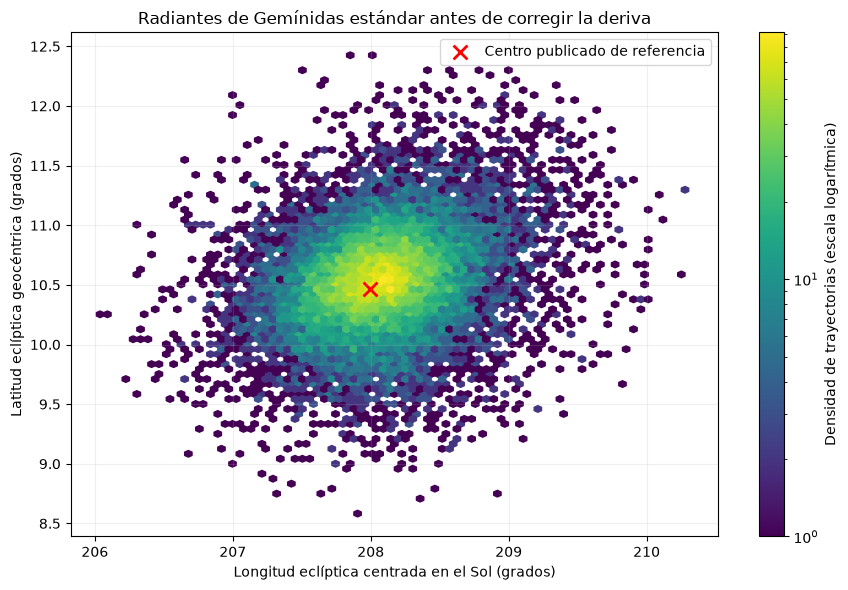

In [35]:
# Visualizar la distribución preliminar de radiantes estándar en coordenadas eclípticas centradas en el Sol

fig, ax = plt.subplots(figsize = (9, 6))

grafico_densidad = ax.hexbin(
    df_gem_estandar["lambda_sce_deg"],
    df_gem_estandar["BETgeo (deg)"],
    gridsize=80,
    mincnt=1,
    bins="log",
    cmap="viridis",
)

ax.scatter(
    207.995,
    10.466,
    color="red",
    marker="x",
    s=100,
    linewidths=2,
    label="Centro publicado de referencia",
)

barra_color = fig.colorbar(
    grafico_densidad,
    ax = ax
)

barra_color.set_label("Densidad de trayectorias (escala logarítmica)")

ax.set_xlabel("Longitud eclíptica centrada en el Sol (grados)")
ax.set_ylabel("Latitud eclíptica geocéntrica (grados)")
ax.set_title("Radiantes de Gemínidas estándar antes de corregir la deriva")
ax.legend()
ax.grid(alpha = 0.2)

plt.tight_layout()
plt.show()